In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
from LD.utils.ld_tools import *
from sklearn.cluster import KMeans
import umap
from sklearn.manifold import trustworthiness
from LD.utils.ld_tools import *
from sklearn import datasets
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.preprocessing import StandardScaler


In [19]:
alphas = [1, 20]
dim_reduction = 2

# # --- IRIS --- #
# points0 = datasets.load_iris().data

# # --- MNIST --- #
# (x_train, _), (x_test, _) = mnist.load_data()
# # images = np.concatenate((x_train, x_test), axis=0)
# images = x_test
# points0 = images.reshape(images.shape[0], -1)
# points0 = points0 / 255.0

# # --- DIGITS --- #
# points0, _ = datasets.load_digits(return_X_y=True)

# --- SWISS ROLL --- #
points0, _ = datasets.make_swiss_roll(n_samples=3000, noise=0.1)

In [20]:
scaler = StandardScaler()
points = scaler.fit_transform(points0)
dist_mat = distance_matrix(points, points)
scores = []

In [21]:
for i in range(alphas[0], alphas[1] + 1):
    fermat_dist_mat = fermat_function(dist_mat, alpha=i)
    umap_reducer_fermat = umap.UMAP(n_components=dim_reduction, metric='precomputed')
    umap_reducer_fermat.fit(fermat_dist_mat)
    points_reduced_fermat = umap_reducer_fermat.embedding_
    dist_mat_umap = distance_matrix(points_reduced_fermat, points_reduced_fermat)
    fermat_umap = fermat_function(dist_mat_umap, alpha=i)
    
    scores.append(trustworthiness(X= fermat_dist_mat, X_embedded= fermat_umap, n_neighbors=20, metric='precomputed'))
    
    percent = i / alphas[1]
    filled_length = int(40 * percent)
    bar = '=' * filled_length + '-' * (40 - filled_length)
    print(f"\033c", end="")
    print(f'\rProgress: |{bar}| {int(percent*100)}%', end='')

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


Progress: |==--------------------------------------| 5%

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


Progress: |====------------------------------------| 10%

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


Progress: |======----------------------------------| 15%

... (30 outputs left out)

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


Progress: |======================================--| 95%

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")


Progress: |========================================| 100%

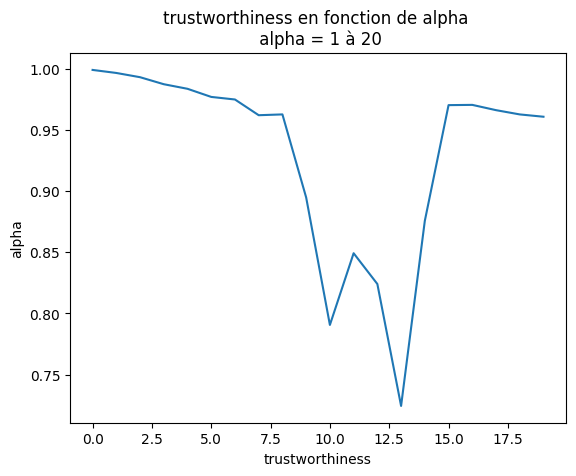

In [22]:
plt.plot(scores)
plt.xlabel("trustworthiness")
plt.ylabel("alpha")
plt.title(f"trustworthiness en fonction de alpha \n alpha = {alphas[0]} à {alphas[1]}")
plt.show()